<a href="https://colab.research.google.com/github/FABYG6/DL_Redes_Neuronales_Basicas/blob/main/Transformers_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

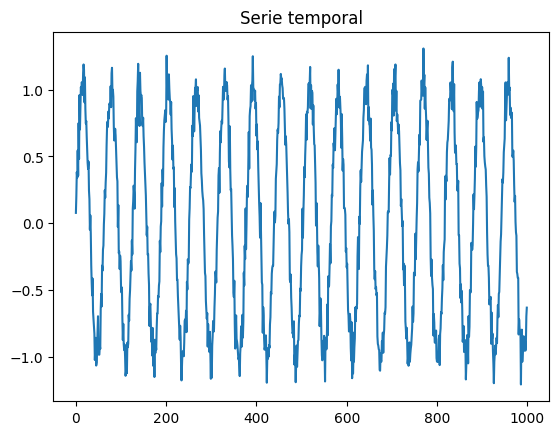

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 172ms/step - loss: 0.6447 - mae: 0.7176 - val_loss: 0.5523 - val_mae: 0.6733
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4796 - mae: 0.6234 - val_loss: 0.4241 - val_mae: 0.5914
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3865 - mae: 0.5649 - val_loss: 0.3533 - val_mae: 0.5387
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3384 - mae: 0.5271 - val_loss: 0.3185 - val_mae: 0.5092
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3185 - mae: 0.5102 - val_loss: 0.3039 - val_mae: 0.4943
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3100 - mae: 0.5014 - val_loss: 0.2988 - val_mae: 0.4873
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3071 - mae: 0.4979 - val_loss: 0.2969 - val_mae: 0.4830
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3066 - mae: 0.4958 - val_loss: 0.2958 - val_mae: 0.4816
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3062 - mae

In [2]:
# Mecanismo de Atención para Series de Tiempo
# Importación de librerías
import numpy as np
import matplotlib.pyplot as plt

# Creación de la serie temporal sintética
t = np.arange(0,100,0.1)
serie = np.sin(t) + np.random.normal(0,0.1,len(t))

# Visualización de la serie
plt.plot(serie)
plt.title("Serie temporal")
plt.show()

# # Creación de ventanas temporales
def crear_ventanas(datos, ventana):

    X = []
    y = []

    for i in range(len(datos)-ventana):
        X.append(datos[i:i+ventana])
        y.append(datos[i+ventana])
    return np.array(X), np.array(y)

# Construcción del conjunto de entrenamiento
X, y = crear_ventanas(serie,20)

# Importación de capas para el modelo
import tensorflow as tf

from tensorflow.keras.layers import Input # recibe los datos.
from tensorflow.keras.layers import Dense # realiza transformaciones de información.
from tensorflow.keras.layers import Attention # implementa el mecanismo de atención.
from tensorflow.keras.models import Model # construye la arquitectura completa.

# Definición de entrada
inputs = Input(shape=(20,1))  # 20 pasos temporales, 1 característica por paso

# Aplicación de Atención
attention = Attention()([inputs, inputs])

# Capa oculta
dense = Dense(
32,
activation='relu'
)(attention)

# Capa de salida
output = Dense(1)(
    dense[:,-1,:]
)

# Construcción del modelo
model = Model(inputs, output)

# Compilación
model.compile(
optimizer='adam',
loss='mse',
metrics=['mae']
)

# Entrenamiento
history = model.fit(
    X.reshape(-1,20,1),
    y,
    epochs=20, # Número de iteraciones completas sobre los datos
    batch_size=32,  # Cantidad de muestras procesadas simultáneamente
    validation_split=0.2  # 20% reservado para validación
)

# Evaluación
loss, mae = model.evaluate(
    X.reshape(-1,20,1),
    y
)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 335ms/step - loss: 0.2009 - mae: 0.3399 - val_loss: 0.0699 - val_mae: 0.2265
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 0.0347 - mae: 0.1526 - val_loss: 0.0275 - val_mae: 0.1342
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0188 - mae: 0.1094 - val_loss: 0.0181 - val_mae: 0.1094
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0177 - mae: 0.1063 - val_loss: 0.0165 - val_mae: 0.1038
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0187 - mae: 0.1091 - val_loss: 0.0182 - val_mae: 0.1096
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0162 - mae: 0.1015 - val_loss: 0.0161 - val_mae: 0.1051
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0193 - mae: 0.1082 - val_loss: 0.0290 - val_mae: 0.1390
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0204 - mae: 0.1144 - val_loss: 0.0332 - val_mae: 0.1545
Epoch 9/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0177 - m

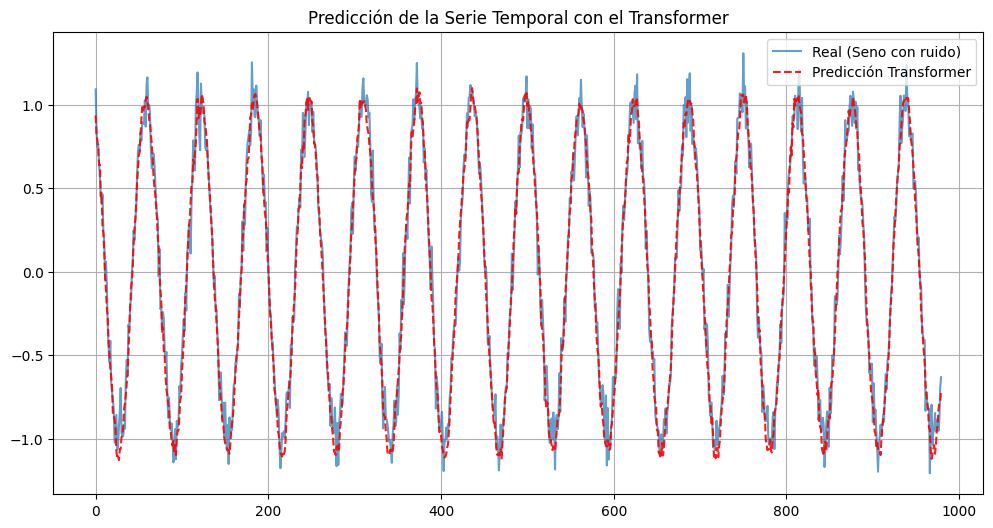

In [3]:
# Transformer Básico para Series de Tiempo
# Importación de Librerías
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization, Dense, Input, Flatten, Add
from tensorflow.keras.models import Model

# Definir entrada
inputs = Input(shape=(20, 1))

# Proyectamos la entrada de (20, 1) a (20, 32)
x = Dense(32)(inputs)

# --- POSITIONAL ENCODING CORREGIDO PARA EL BATCH ---
# Usamos una capa no entrenable o pesos fijos que se suman directamente de forma compatible
class PositionalEmbedding(tf.keras.layers.Layer):
    def __init__(self, seq_len, d_model, **kwargs):
        super(PositionalEmbedding, self).__init__(**kwargs)
        self.pos_embeddings = self.add_weight(
            shape=(seq_len, d_model),
            initializer="glorot_uniform",
            trainable=True,
            name="pos_embedding"
        )

    def call(self, inputs):
        # Se suma el embedding de posición que se transmite automáticamente para todo el batch
        return inputs + self.pos_embeddings

x_positioned = PositionalEmbedding(seq_len=20, d_model=32)(x)

# Multi-Head Attention
attention_output = MultiHeadAttention(
    num_heads=4,
    key_dim=32
)(
    x_positioned,
    x_positioned
)

# Conexión residual y Normalización
x = Add()([x_positioned, attention_output])
x = LayerNormalization()(x)

# Feed Forward Network (FFN)
ffn = Dense(64, activation='relu')(x)
ffn = Dense(32)(ffn)

# Segunda conexión residual y Normalización
x = Add()([x, ffn])
x = LayerNormalization()(x)

# Aplanamos la secuencia (20 * 32) para conectarla a la salida densa
x = Flatten()(x)

# Capas densas de salida
x = Dense(32, activation='relu')(x)
outputs = Dense(1)(x)

# Construcción del Transformer
transformer = Model(inputs, outputs)

# Compilación
transformer.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Entrenamiento
history = transformer.fit(
    X.reshape(-1, 20, 1),
    y,
    epochs=30,
    batch_size=32,
    validation_split=0.2
)

# Predicción
pred = transformer.predict(X.reshape(-1, 20, 1))

# Comparación gráfica
plt.figure(figsize=(12, 6))
plt.plot(y, label='Real (Seno con ruido)', alpha=0.7)
plt.plot(pred, label='Predicción Transformer', linestyle='--', color='red', alpha=0.9)
plt.title("Predicción de la Serie Temporal con el Transformer")
plt.legend()
plt.grid(True)
plt.show()